This Notebook runs with 
* python3.13
* pandas
* matplotlib
* numpy

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
#import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [3]:
from plotting_ts_tools import *

In [4]:
# Select Variables
#
# 50 mm sind sehr wenige
# TR, Regcm hat zu viele sieht komisch aus
#climate_index='R20mm' 
#climate_index= 'DD'
climate_index= 'TG'
#climate_index= 'TX'
#climate_index= 'TN'
#climate_index='SU40'
#climate_index='SU35'
#climate_index='TR'
#climate_index='TR26'
#climate_index='RRm'
#climate_index='FG'
#climate_index='RR1'


var_meta = select_index(climate_index)
print(var_meta)
# select country and time step
#
#country='Togo'
country='Burkina Faso'
#country='Ivory Coast'
timestep='year'


{'longname': 'mean temperature [°C]', 'longnameK': 'mean temperature [K]', 'unit_base': '°C', 'unit_alt': 'K', 'description': 'Near-surface air temperature'}


In [5]:
wkdir = os.getcwd()
datadir = wkdir.replace("TIMESERIES", "data/spavg/spavg_afr22")

In [6]:
# Load the CSV file containing the data for the selected index, country, and time step:
#
file_name='climdexCORDEX_AFR22_'+climate_index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(datadir,file_name)
data = pd.read_csv(file_path)

In [7]:
# define output path and filename

outputpath = wkdir.replace("Notebooks/TIMESERIES", "PLOTS/AFR22_timeseries/"+climate_index)

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [8]:
# The data needs to be cut to the same length for all scenarios and the same time period for all indices.
# cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)
# For TG, we need to load the data with longnameK to convert from K to °C in the load function. 
# For the other indices, we can load the data without longnameK.
#

if climate_index in ['TN', 'TX', 'TG']:
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31', longnameK=var_meta['longnameK'])
else:
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31')

Data after cleanup: 
42        AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
97        AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
152       AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
207       AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
262       AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
                                ...                        
135452    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135507    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135562    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135617    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135672    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
Name: realization, Length: 2467, dtype: str
42                   MOHC-HadGEM2-ES
97                   MOHC-HadGEM2-ES
152                  MOHC-HadGEM2-ES
207                  MOHC-HadGEM2-ES
262                  MOHC-HadGEM2-ES
                     ...            
135452    NCC-NorESM1-MNCC-NorESM1-M
135507    NCC-No

In [305]:
# Update metadata for RRm to yearly units
if climate_index == "RRm":
    var_meta["longname"] = var_meta["longname"].replace("mm/day", "mm/year")
    var_meta["unit_base"] = "mm/year"

print(var_meta)

{'longname': 'Mean daily mean wind speed [m/s]', 'unit_base': 'm/s', 'description': 'Mean daily mean wind speed'}


In [9]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
print(var_meta['longname'])    
df_anomaly_year = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', var_meta['longname'])
#df.head()

mean temperature [°C]


In [10]:
# Mean anomaly per time slice, for each realization and scenario
# Use pre-defined `slices` if available; otherwise fall back to standard ranges
slices_to_use = [
        ("2031-2060", 2031, 2060),
        ("2069-2098", 2069, 2098),
    ]
anom_slice_means = calculate_anomaly_timeslice(df_anomaly_year, slices_to_use)
#anom_slice_means.head()

Saving figure to /Users/Buelow/github/factsheet_africa/PLOTS/AFR22_timeseries/TG/TG_Burkina_Faso_timeseries_box_minmax_p15p85_oT.png


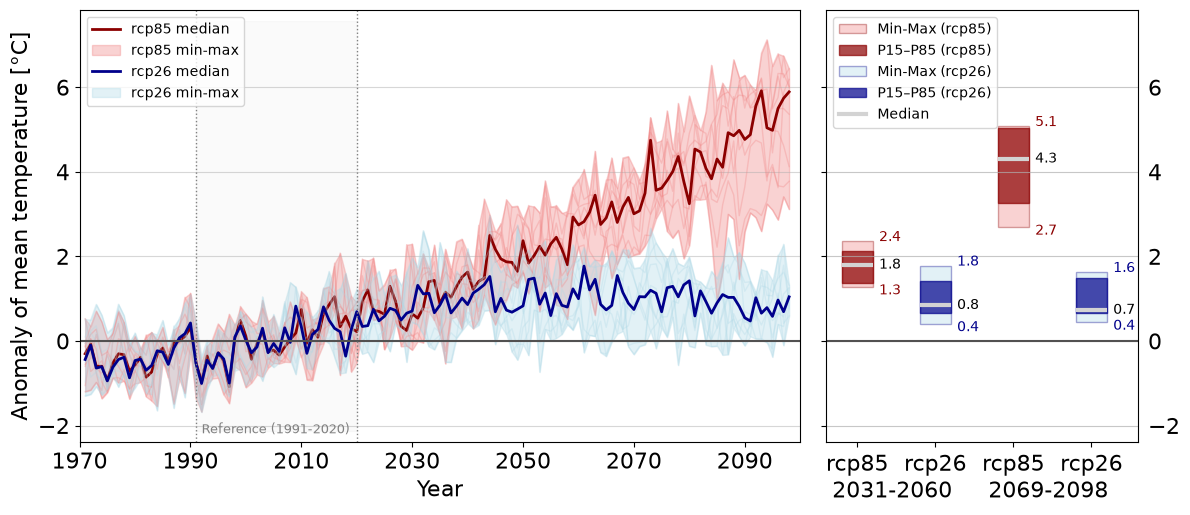

In [11]:
# now line plot with era5 and box plot beside each other in one figure:
# Increased label font sizes
#removed ERA5 for now outof the plotting function.
lineplot_and_boxplot(df_anomaly_year,anom_slice_means, country, climate_index, var_meta['longname'], outputpath)